# Probability Distributions

**AIM 402 — Statistics for Data Analysis using Python**

**Main idea:** a probability distribution describes the possible values of a variable and how likely those values are.


**How to use this notebook:** each section gives the idea in words, then the formula, then one worked example by hand, then the same answer in Python. Run every code cell as we go.

## 1. Two types of data

Before choosing a distribution, decide what kind of data you have.

| Discrete data | Continuous data |
| --- | --- |
| We **count** it | We **measure** it |
| Number of customers | Waiting time |
| Number of defective products | Weight |
| Number of calls | Temperature |

- **Discrete:** usually whole-number counts such as 0, 1, 2, 3, ...
- **Continuous:** any value inside a range, such as 2.1, 2.15 or 2.153.

**In plain words:** if you can count it on your fingers, it is discrete. If you need a ruler, a scale or a clock, it is continuous.

This one decision already narrows the choice: Binomial and Poisson are for counts, Normal and Lognormal are for measurements.


It also decides **how** we write the probability down — a PMF for counts, a PDF for measurements. That is section 2.

## Random variables and distributions

A **random variable** assigns a numerical value to the outcome of a random process.

| Type | Values | Probability function | Examples |
|---|---|---|---|
| Discrete | Countable values | Probability mass function, PMF | Number of defective products, website clicks |
| Continuous | Any value in an interval | Probability density function, PDF | Height, temperature, delivery time |

For a discrete random variable $X$, the PMF gives:

$$P(X=x)$$

For a continuous random variable, the PDF gives density rather than direct probability. Probabilities come from areas under the curve:

$$P(a \le X \le b) = \int_a^b f(x)\,dx$$

### Expected value and variance

- **Expected value** is the long-run average: $E[X]=\mu$.
- **Variance** measures spread around the mean: $\operatorname{Var}(X)=E[(X-\mu)^2]$.
- **Standard deviation** is $\sigma=\sqrt{\operatorname{Var}(X)}$.

In [51]:
# Setup: run this cell first
import math
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

rng = np.random.default_rng(42)          # fixed seed, so everyone sees the same numbers
plt.rcParams["figure.figsize"] = (7, 4)
plt.rcParams["axes.grid"] = True

print("Setup complete.")

Setup complete.


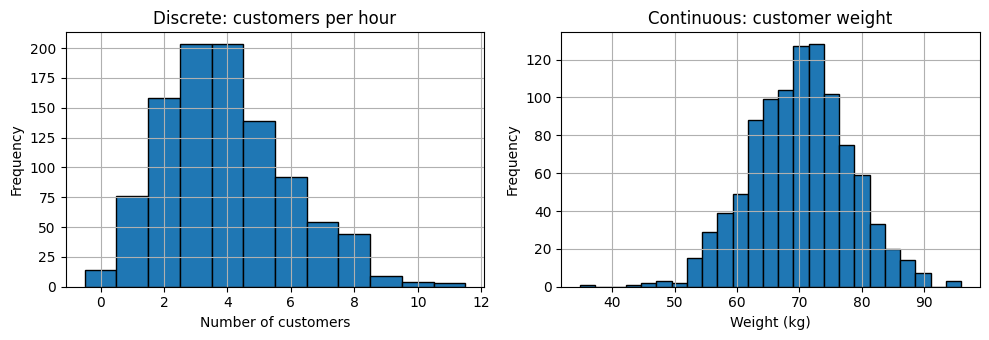

Left: separate bars, whole numbers only.  Right: a smooth spread of measured values.


In [52]:
# Example graphs: count data on the left, measured data on the right
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))

counts = rng.poisson(4, 1000)
ax[0].hist(counts, bins=np.arange(-0.5, 12.5, 1), edgecolor="black")
ax[0].set_title("Discrete: customers per hour")
ax[0].set_xlabel("Number of customers")
ax[0].set_ylabel("Frequency")

weights = rng.normal(70, 8, 1000)
ax[1].hist(weights, bins=25, edgecolor="black")
ax[1].set_title("Continuous: customer weight")
ax[1].set_xlabel("Weight (kg)")
ax[1].set_ylabel("Frequency")

plt.tight_layout()
plt.show()

print("Left: separate bars, whole numbers only.  Right: a smooth spread of measured values.")

## 2. PMF and PDF — the two ways to write a distribution

### Why do we need two?

Because of section 1. **Counted data and measured data behave differently**, so probability has to be written down differently for each.

### Discrete data → PMF (probability mass function)

With counts there is a separate, countable list of possible values: 0, 1, 2, 3, ...
Each value can carry a real probability, so we can simply ask "how likely is exactly 2?"

- $P(X = x)$ **is a genuine probability**, always between 0 and 1.
- All the values add up to 1: $\sum_x P(X = x) = 1$.
- Drawn as **separate bars**.
- **The Binomial and Poisson formulas are PMFs.**
- In Python: `stats.binom.pmf(...)`, `stats.poisson.pmf(...)`

### Continuous data → PDF (probability density function)

With measurements there are **infinitely many** possible values. A weight could be 70 kg, or 70.1, or 70.14, or 70.1437...

Ask "what is the probability of exactly 70.000000... kg?" and the honest answer is **zero** — no one is ever *exactly* that weight. So a list of probabilities per value would be a list of zeros, which tells us nothing.

Instead we describe how **concentrated** the values are at each point:

- $f(x)$ is a **density**, not a probability. It is the **height of the curve** at $x$.
- A density **can be larger than 1** — that alone proves it is not a probability.
- Probability is the **area under the curve** over an interval.
- The total area is 1.
- Drawn as a **smooth curve**.
- **The Normal and Lognormal formulas are PDFs.**
- In Python: `stats.norm.pdf(...)`, `stats.lognorm.pdf(...)`

### Side by side

| | PMF (discrete) | PDF (continuous) |
| --- | --- | --- |
| Stands for | probability **mass** function | probability **density** function |
| Used for | Binomial, Poisson | Normal, Lognormal |
| $f(x)$ gives you | the probability of exactly $x$ | the height (density) at $x$ |
| Is $f(x)$ a probability? | **Yes** | **No** |
| Can $f(x)$ be above 1? | No | **Yes** |
| $P(X = \text{one exact value})$ | can be more than 0 | always **0** |
| Probability comes from | adding up bars | **area** under the curve |
| Everything adds to | 1 | 1 |
| Picture | bars | smooth curve |

### Getting an actual probability out of a PDF: the CDF

Since the height of a PDF is not a probability, continuous questions are answered with the **cumulative distribution function**:

$$F(x) = P(X \le x) \qquad \text{— the area to the left of } x$$

and for an interval:

$$P(a < X < b) = F(b) - F(a)$$

In Python: `stats.norm.cdf(...)`. We use it in section 6 to find the percentage of students scoring below 85.

**The most common mistake:** reading the height of a bell curve as a probability. The height is density. **Probability is area.**

In [53]:
# PMF value is a probability and a PDF value is not

# PMF - discrete: this IS a probability # stats.binom.pmf(k, n, p) # 
print("PMF  stats.binom.pmf(2, 5, 0.4) =", round(stats.binom.pmf(2, 5, 0.4), 4),
      "-> a real probability (34.56%)")
all_bars = stats.binom.pmf(np.arange(0, 6), 5, 0.4)
print("     all the bars add to          =", round(all_bars.sum(), 4))
print()

PMF  stats.binom.pmf(2, 5, 0.4) = 0.3456 -> a real probability (34.56%)
     all the bars add to          = 1.0



In [54]:
# PDF - continuous: this is NOT a probability, it is a height # stats.norm.pdf(x, mean, standard_deviation)
print("PDF  stats.norm.pdf(70, 70, 10)  =", round(stats.norm.pdf(70, 70, 10), 4),
      "-> just the height of the curve")
print("     stats.norm.pdf(0, 0, 0.1)   =", round(stats.norm.pdf(0, 0, 0.1), 4),
      "-> ABOVE 1, so it cannot be a probability")
print()

# For continuous data, the probability of one exact value is zero
exact = stats.norm.cdf(70, 70, 10) - stats.norm.cdf(70, 70, 10)
print("P(weight is exactly 70.000...) =", exact, "-> always zero for continuous data")
print()

PDF  stats.norm.pdf(70, 70, 10)  = 0.0399 -> just the height of the curve
     stats.norm.pdf(0, 0, 0.1)   = 3.9894 -> ABOVE 1, so it cannot be a probability

P(weight is exactly 70.000...) = 0.0 -> always zero for continuous data



In [55]:

# Probability for continuous data = area, found with the CDF, within the limits of 60 to 80
area = stats.norm.cdf(80, 70, 10) - stats.norm.cdf(60, 70, 10)
print("P(60 < X < 80) = F(80) - F(60) =", round(area, 4), "=", round(area * 100, 2), "%")
print("                                 -> this is an AREA, and it is a real probability")
print()
print("Notice: 60 to 80 is the mean plus or minus 1 SD, and the area is 68.27%.")
print("That is where the Empirical Rule's 68% comes from - see section 9.")

P(60 < X < 80) = F(80) - F(60) = 0.6827 = 68.27 %
                                 -> this is an AREA, and it is a real probability

Notice: 60 to 80 is the mean plus or minus 1 SD, and the area is 68.27%.
That is where the Empirical Rule's 68% comes from - see section 9.


## 3. The four distributions at a glance

Learn the question each one answers. The formulas come later.

| Distribution | Data | The question it answers |
| --- | --- | --- |
| **Binomial** | Discrete | How many **successes** in a fixed number of attempts? |
| **Poisson** | Discrete | How many **events** in a fixed time or area? |
| **Normal** | Continuous | Are most values near the average, with fewer at both ends? |
| **Lognormal** | Continuous | Are most values small, with a few very large ones? |

**Examples to keep in mind**

- **Binomial** — 20 customers are each asked whether they will buy. Each answer is yes or no. *How many say yes?*
- **Poisson** — a shop is open for one hour. *How many customers arrive?*
- **Normal** — adult heights, or measurement errors. *Balanced around the average.*
- **Lognormal** — income, or house prices. *A long tail to the right.*

Run the next cell and look at the four shapes before we study them one by one.

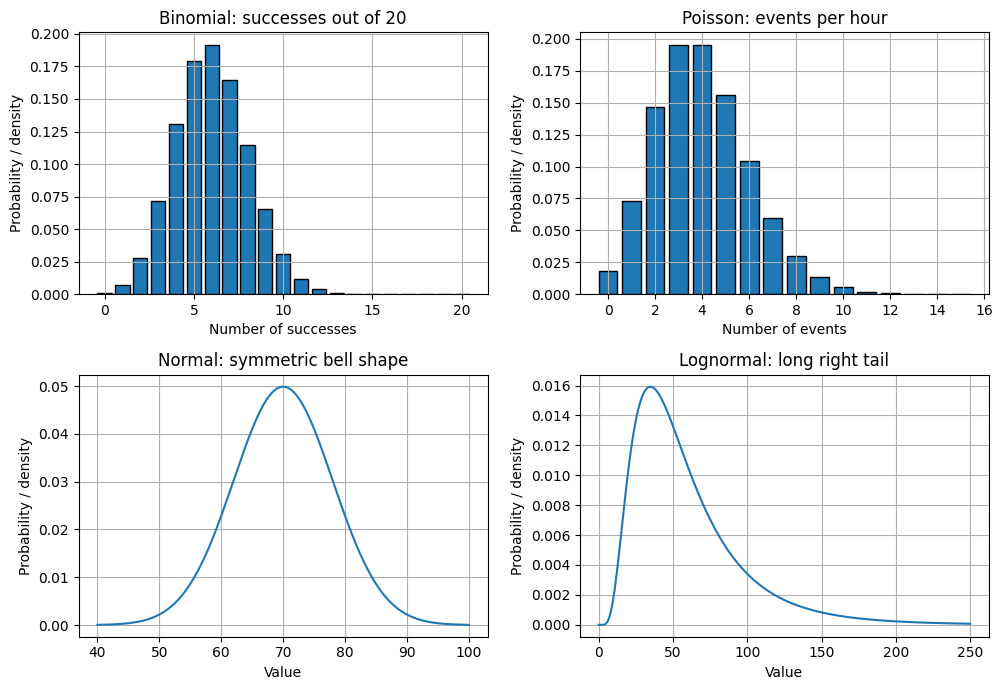

Top row: counts, drawn as separate bars.  Bottom row: measurements, drawn as curves.


In [56]:
# The four shapes side by side
fig, ax = plt.subplots(2, 2, figsize=(10, 7))

# Binomial: 20 attempts, success probability 0.3
x = np.arange(0, 21)
ax[0, 0].bar(x, stats.binom.pmf(x, n=20, p=0.3), edgecolor="black")
ax[0, 0].set_title("Binomial: successes out of 20")
ax[0, 0].set_xlabel("Number of successes")

# Poisson: average 4 events per hour
x = np.arange(0, 16)
ax[0, 1].bar(x, stats.poisson.pmf(x, mu=4), edgecolor="black")
ax[0, 1].set_title("Poisson: events per hour")
ax[0, 1].set_xlabel("Number of events")

# Normal: mean 70, sd 8
x = np.linspace(40, 100, 300)
ax[1, 0].plot(x, stats.norm.pdf(x, loc=70, scale=8))
ax[1, 0].set_title("Normal: symmetric bell shape")
ax[1, 0].set_xlabel("Value")

# Lognormal: positive values, long right tail
x = np.linspace(0.01, 250, 300)
ax[1, 1].plot(x, stats.lognorm.pdf(x, s=0.6, scale=50))
ax[1, 1].set_title("Lognormal: long right tail")
ax[1, 1].set_xlabel("Value")

for a in ax.flat:
    a.set_ylabel("Probability / density")

plt.tight_layout()
plt.show()

print("Top row: counts, drawn as separate bars.  Bottom row: measurements, drawn as curves.")

## 4. Binomial distribution

The Binomial distribution gives the probability of getting a certain number of **successes** in a **fixed** number of attempts.

### Real-world use cases
- How many customers out of 20 will buy a product?
- How many products out of 10 are defective?
- How many students out of 30 will pass an exam?
- How many emails out of 15 are spam?

### When should we use it? — four conditions
1. The number of attempts is **fixed**.
2. Each attempt has only **two outcomes**: success or failure.
3. The attempts are **independent**.
4. The probability of success **stays the same** for every attempt.

### Formula

$$P(X = x) = \binom{n}{x}\, p^{x}\, (1-p)^{\,n-x}$$

**This formula is a PMF** (section 2). The data are counts, so $P(X = x)$ is a genuine probability and in Python we call `.pmf()`.

Where:

- $P(X = x)$ — probability of exactly $x$ successes
- $n$ — total number of attempts
- $x$ — number of successes we want
- $p$ — probability of success in one attempt
- $1 - p$ — probability of failure
- $\binom{n}{x} = \dfrac{n!}{x!\,(n-x)!}$ — the number of ways to arrange the successes

### Calcualte example (by hand)

A shop asks 5 customers whether they will buy a product. Each customer has a 0.4 probability of buying.
**What is the probability that exactly 2 customers buy?**

Given: $n = 5$, $x = 2$, $p = 0.4$, $1 - p = 0.6$.


**Answer: 0.3456, or 34.56%.**

*Interpretation:* under these assumptions, there is a 34.56% probability that exactly 2 of the 5 customers buy the product.

### Mean and variance

$$\text{Mean} = \mu = np \qquad\qquad \text{Variance} = \sigma^{2} = np(1-p)$$

For this example: mean $= 5(0.4) = 2$ customers, variance $= 5(0.4)(0.6) = 1.2$.

**Remember:** Binomial = successes out of a fixed number of attempts.

In [57]:
# Binomial by hand, then checked with SciPy
n = 5      # number of attempts
p = 0.4    # probability of success in one attempt
x = 2      # number of successes we want

probability = math.comb(n, x) * (p ** x) * ((1 - p) ** (n - x))

print("By hand   P(X = 2) =", round(probability, 4))
print("Percentage         =", round(probability * 100, 2), "%")
print("SciPy     P(X = 2) =", round(stats.binom.pmf(x, n, p), 4))
print()
print("Mean     = n*p       =", n * p)
print("Variance = n*p*(1-p) =", n * p * (1 - p))

By hand   P(X = 2) = 0.3456
Percentage         = 34.56 %
SciPy     P(X = 2) = 0.3456

Mean     = n*p       = 2.0
Variance = n*p*(1-p) = 1.2


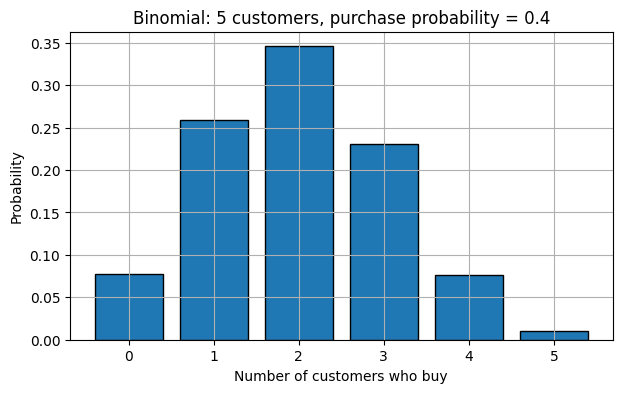

P(X = 0) = 0.0778
P(X = 1) = 0.2592
P(X = 2) = 0.3456
P(X = 3) = 0.2304
P(X = 4) = 0.0768
P(X = 5) = 0.0102
Total = 1.0 (all probabilities add up to 1)


In [58]:
# Probability of every possible number of purchases
x_values = np.arange(0, n + 1)
probabilities = stats.binom.pmf(x_values, n, p)

plt.bar(x_values, probabilities, edgecolor="black")
plt.title("Binomial: 5 customers, purchase probability = 0.4")
plt.xlabel("Number of customers who buy")
plt.ylabel("Probability")
plt.xticks(x_values)
plt.show()

for value, prob in zip(x_values, probabilities):
    print(f"P(X = {value}) = {prob:.4f}")
print("Total =", round(probabilities.sum(), 4), "(all probabilities add up to 1)")

## 5. Poisson distribution

The Poisson distribution gives the probability of a certain number of **events** happening in a **fixed period of time or area**, when events occur at a reasonably constant average rate.

### Real-world use cases
- Number of customers arriving at a shop in one hour.
- Number of calls received by a help desk in 10 minutes.
- Number of typing errors on a page.
- Number of machine breakdowns in a week.

### When should we use it? — four conditions
1. We count how many events happen in a **fixed interval**.
2. Events occur **independently**.
3. The average rate is **reasonably constant** over the interval.
4. Events occur **one at a time**.

### Formula

$$P(X = x) = \frac{e^{-\lambda}\,\lambda^{x}}{x!}$$

**This formula is a PMF** (section 2) — another count, so again `.pmf()` in Python.

Where:

- $P(X = x)$ — probability of exactly $x$ events
- $x$ — number of events we are interested in
- $\lambda$ (lambda) — average number of events in the interval
- $e$ — mathematical constant, about 2.71828
- $x!$ — factorial of $x$

### Calculation example (by hand)

A shop receives an average of 3 customers every 10 minutes.
**What is the probability that exactly 2 customers arrive in the next 10 minutes?**

Given: $\lambda = 3$, $x = 2$.


**Answer: about 0.2240, or 22.40%.**

*Interpretation:* if the average rate stays at 3 customers per 10 minutes and the Poisson conditions are reasonable, the probability of exactly 2 arrivals in a 10-minute period is about 22.4%.

### Mean and variance

$$\text{Mean} = \lambda \qquad\qquad \text{Variance} = \lambda$$

For this example both are 3. This is a useful check: if the mean and variance of count data are very different, Poisson may not be the right model.

**Remember:** Poisson = events in a fixed time or space interval.

In [59]:
# Poisson by hand, then checked with SciPy
lam = 3    # average number of events in the interval
x = 2      # number of events we want

probability = (math.exp(-lam) * (lam ** x)) / math.factorial(x)

print("By hand   P(X = 2) =", round(probability, 4))
print("Percentage         =", round(probability * 100, 2), "%")
print("SciPy     P(X = 2) =", round(stats.poisson.pmf(x, mu=lam), 4))
print()
print("Mean     =", lam)
print("Variance =", lam)

By hand   P(X = 2) = 0.224
Percentage         = 22.4 %
SciPy     P(X = 2) = 0.224

Mean     = 3
Variance = 3


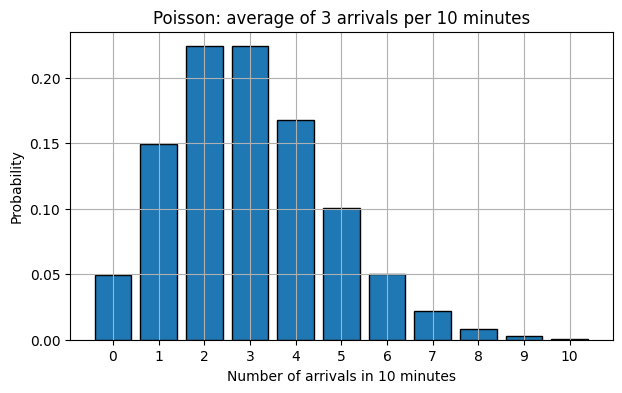

Most likely counts are 2 and 3:
P(X = 2) = 0.224
P(X = 3) = 0.224
P(X = 0) = 0.0498 (a quiet 10 minutes)


In [60]:
# Probability of different arrival counts
x_values = np.arange(0, 11)
probabilities = stats.poisson.pmf(x_values, mu=lam)

plt.bar(x_values, probabilities, edgecolor="black")
plt.title("Poisson: average of 3 arrivals per 10 minutes")
plt.xlabel("Number of arrivals in 10 minutes")
plt.ylabel("Probability")
plt.xticks(x_values)
plt.show()

print("Most likely counts are 2 and 3:")
print("P(X = 2) =", round(stats.poisson.pmf(2, mu=lam), 4))
print("P(X = 3) =", round(stats.poisson.pmf(3, mu=lam), 4))
print("P(X = 0) =", round(stats.poisson.pmf(0, mu=lam), 4), "(a quiet 10 minutes)")

## 6. Normal distribution

The Normal distribution is a **continuous, bell-shaped** distribution. Values gather around the mean and the two sides are roughly symmetric.

### Real-world use cases
- Human heights within a suitable population group.
- Measurement errors.
- Some examination scores.
- Manufacturing measurements, such as the diameter of a product, when the process is stable.

Not every real dataset is normal. **Check the shape before using normal-distribution methods.**

### Main characteristics
- The curve is symmetric around the mean.
- Mean = median = mode for an ideal normal distribution.
- The total area under the curve is 1 (100%).
- The **mean** sets the centre; the **standard deviation** sets the spread.

### Formula: probability density

$$f(x) = \frac{1}{\sigma\sqrt{2\pi}}\, e^{-\frac{(x-\mu)^{2}}{2\sigma^{2}}}$$

Where:

- $x$ — the value being considered
- $\mu$ — population mean
- $\sigma$ — population standard deviation
- $\pi \approx 3.14159$, $e \approx 2.71828$

**This formula is a PDF** (section 2). It gives the *height* of the curve at a value, **not** a probability. For continuous data the probability of one exact value is zero — probability is the **area under the curve** over an interval.

So in Python we use two functions here: `stats.norm.pdf()` to **draw** the curve, and `stats.norm.cdf()` to get an actual **probability** (the area to the left of a value).

### Z-score formula

$$z = \frac{x - \mu}{\sigma}$$

The z-score says how many standard deviations a value sits above or below the mean.

### Calculation example (by hand)

Examination marks are approximately normal with mean $\mu = 70$ and standard deviation $\sigma = 10$. A student scores 85.


**Answer: $z = 1.5$.**

*Interpretation:* the student's mark is 1.5 standard deviations above the average. From the normal table, about 93.3% of students score below 85.

### The Empirical Rule for this example

| Range | Marks | Approximate share |
| --- | --- | --- |
| Within 1 SD | 60 to 80 | about 68% |
| Within 2 SD | 50 to 90 | about 95% |
| Within 3 SD | 40 to 100 | about 99.7% |

**Remember:** Normal = continuous, symmetric, bell-shaped.

By hand   z = (85 - 70) / 10 = 1.5
SciPy     percentage below 85 = 93.32 %
          percentage above 85 = 6.68 %


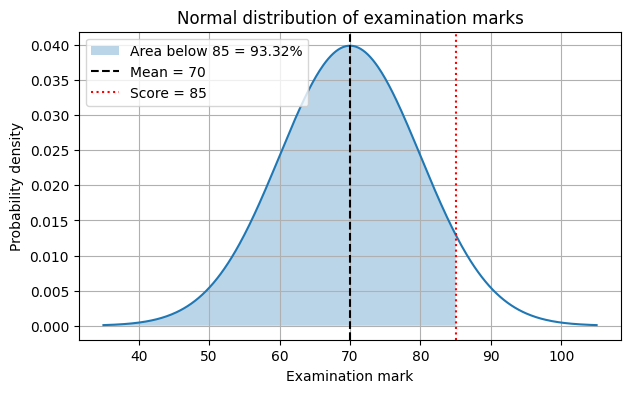

In [61]:
# Normal by hand, then checked with SciPy
mean = 70
sd = 10
score = 85

z = (score - mean) / sd
percent_below = stats.norm.cdf(score, loc=mean, scale=sd) * 100

print("By hand   z = (85 - 70) / 10 =", round(z, 2))
print("SciPy     percentage below 85 =", round(percent_below, 2), "%")
print("          percentage above 85 =", round(100 - percent_below, 2), "%")

# Draw the curve
x = np.linspace(35, 105, 400)
y = stats.norm.pdf(x, loc=mean, scale=sd)

plt.plot(x, y)
plt.fill_between(x, y, where=(x <= score), alpha=0.3,
                 label="Area below 85 = 93.32%")
plt.axvline(mean, linestyle="--", color="black", label="Mean = 70")
plt.axvline(score, linestyle=":", color="red", label="Score = 85")
plt.title("Normal distribution of examination marks")
plt.xlabel("Examination mark")
plt.ylabel("Probability density")
plt.legend()
plt.show()

## 7. Lognormal distribution

A variable is **Lognormal** when its **natural logarithm** is Normal.

In simple terms:
- All values are **positive**.
- Most observations are small or moderate.
- A few observations are very large.
- The graph has a **long tail to the right**.

### Real-world use cases
- Personal income.
- House prices.
- Some financial prices and insurance claim sizes.
- Measurements produced by several multiplying factors.

**Important:** these variables are not always lognormal. Look at the data and check whether the model is suitable.

### Main idea and formula

If $X$ is lognormal, then

$$Y = \ln(X) \quad\text{follows}\quad Y \sim N(\mu,\ \sigma^{2})$$

The density is

$$f(x) = \frac{1}{x\,\sigma\sqrt{2\pi}}\, e^{-\frac{(\ln x - \mu)^{2}}{2\sigma^{2}}}, \qquad x > 0$$

**This formula is a PDF** (section 2) — continuous data again, so the curve's height is a density and probability is area.

Where $\mu$ and $\sigma$ are the mean and standard deviation **of the logged values**, not of the original data.

### Useful values

$$\text{Median} = e^{\mu} \qquad\qquad \text{Mean} = e^{\mu + \frac{\sigma^{2}}{2}}$$

The mean is larger than the median, because the long right tail pulls the mean upwards.

### Worked example (by hand)

Suppose the natural logarithm of house prices is normal with $\mu = 10$ and $\sigma = 0.5$.

$$\text{Median} = e^{10} \approx 22{,}026.47$$

$$\text{Mean} = e^{10 + \frac{0.5^{2}}{2}} = e^{10.125} \approx 24{,}959.26$$

(Both in the currency units of the original price variable.)

*Interpretation:* the mean is about 2,933 higher than the median because a few expensive houses create a long right tail. **The median describes the typical house better than the mean.**

**Remember:** Lognormal = positive, right-skewed data whose logarithm is Normal.

Median on the original scale = e^10     = 22026.47
Mean   on the original scale = e^10.125 = 24959.26
Difference (mean - median)              = 2932.79


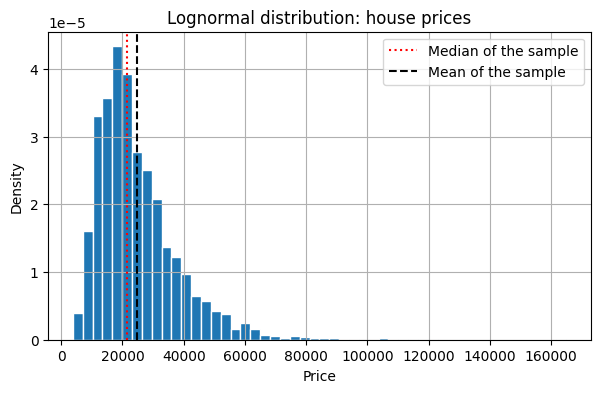


Sample median = 21599.29
Sample mean   = 24898.49 - larger, because of the right tail


In [62]:
# Lognormal by hand
mu_log = 10      # mean of the LOGGED values
sigma_log = 0.5  # standard deviation of the LOGGED values

median_value = math.exp(mu_log)
mean_value = math.exp(mu_log + (sigma_log ** 2) / 2)

print("Median on the original scale = e^10     =", round(median_value, 2))
print("Mean   on the original scale = e^10.125 =", round(mean_value, 2))
print("Difference (mean - median)              =", round(mean_value - median_value, 2))

# Generate example data and look at the shape
data = rng.lognormal(mean=mu_log, sigma=sigma_log, size=5000)

plt.hist(data, bins=50, density=True, edgecolor="white")
plt.axvline(np.median(data), linestyle=":", color="red", label="Median of the sample")
plt.axvline(np.mean(data), linestyle="--", color="black", label="Mean of the sample")
plt.title("Lognormal distribution: house prices")
plt.xlabel("Price")
plt.ylabel("Density")
plt.legend()
plt.show()

print()
print("Sample median =", round(np.median(data), 2))
print("Sample mean   =", round(np.mean(data), 2), "- larger, because of the right tail")

## 8. Reading the shape: symmetric or skewed?

- **Symmetric** — left and right sides look balanced. Mean and median are close.
- **Right-skewed** — a few large values stretch the graph to the right. **Mean > median.**
- **Left-skewed** — a few small values stretch the graph to the left. **Mean < median.**

**In plain words:** the tail pulls the mean towards it. The median stays where most of the data are.

**Example:** a small number of people with very high incomes pulls the average income upwards. The median gives a better picture of the typical person.

**Quick rule for the classroom**

| What you see | Shape | Which average to report |
| --- | --- | --- |
| Mean ≈ median | Symmetric | Either |
| Mean clearly above median | Right-skewed | Median |
| Mean clearly below median | Left-skewed | Median |

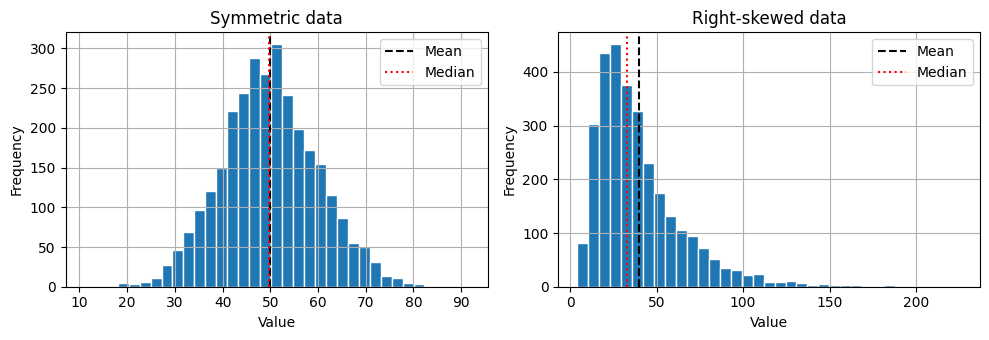

Symmetric    : mean = 49.91 | median = 49.75 -> very close
Right-skewed : mean = 39.86 | median = 33.05 -> mean is pulled up by the tail


In [63]:
# Compare a symmetric dataset with a right-skewed dataset
symmetric = rng.normal(50, 10, 3000)
right_skewed = rng.lognormal(mean=3.5, sigma=0.6, size=3000)

fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
for a, dataset, label in [(ax[0], symmetric, "Symmetric data"),
                          (ax[1], right_skewed, "Right-skewed data")]:
    a.hist(dataset, bins=35, edgecolor="white")
    a.axvline(np.mean(dataset), linestyle="--", color="black", label="Mean")
    a.axvline(np.median(dataset), linestyle=":", color="red", label="Median")
    a.set_title(label)
    a.set_xlabel("Value")
    a.set_ylabel("Frequency")
    a.legend()

plt.tight_layout()
plt.show()

print("Symmetric    : mean =", round(np.mean(symmetric), 2),
      "| median =", round(np.median(symmetric), 2), "-> very close")
print("Right-skewed : mean =", round(np.mean(right_skewed), 2),
      "| median =", round(np.median(right_skewed), 2), "-> mean is pulled up by the tail")

## 9. Empirical Rule vs Chebyshev's Rule

Both rules say how much of the data sits within a number of standard deviations of the mean. They apply in different situations.

### Empirical Rule — only for approximately normal (bell-shaped) data

- About **68%** of values are within 1 standard deviation of the mean.
- About **95%** are within 2 standard deviations.
- About **99.7%** are within 3 standard deviations.

### Chebyshev's Rule — for **any** distribution with a finite mean and variance

- At least **75%** of values are within 2 standard deviations.
- At least **88.9%** are within 3 standard deviations.

General form, for any $k > 1$:

$$\text{At least } \left(1 - \frac{1}{k^{2}}\right) \text{ of the values lie within } k \text{ standard deviations of the mean.}$$

Check it: $k = 2$ gives $1 - 1/4 = 0.75$; $k = 3$ gives $1 - 1/9 = 0.889$.

### Key difference

| | Empirical Rule | Chebyshev's Rule |
| --- | --- | --- |
| Works for | Approximately normal data only | Any distribution |
| Gives | Approximate percentages | Minimum guarantees |
| Within 2 SD | about 95% | at least 75% |
| Within 3 SD | about 99.7% | at least 88.9% |

**In plain words:** the Empirical Rule is sharper but demands a bell shape. Chebyshev is weaker but always safe. **Check the shape first.**

In [64]:
# Does each rule hold? Test on the two datasets from section 8
def check_rules(dataset, name):
    m = np.mean(dataset)
    s = np.std(dataset)
    print(name)
    print("  k | actual within k SD | Empirical says | Chebyshev says")
    empirical = {1: "about 68%", 2: "about 95%", 3: "about 99.7%"}
    chebyshev = {1: "no guarantee", 2: "at least 75%", 3: "at least 88.9%"}
    for k in [1, 2, 3]:
        actual = np.mean(np.abs(dataset - m) <= k * s) * 100
        print(f"  {k} | {actual:17.1f}% | {empirical[k]:>14} | {chebyshev[k]:>14}")
    print()

check_rules(symmetric, "Symmetric (normal) data - Empirical Rule fits well:")
check_rules(right_skewed, "Right-skewed data - Empirical Rule does NOT fit, but Chebyshev still holds:")

print("Conclusion: for the skewed data the 1 SD and 3 SD figures are clearly off")
print("(78% not 68%, and 98% not 99.7%), so the Empirical Rule should not be used.")
print("Chebyshev's minimums are satisfied by both datasets, as they must be.")

Symmetric (normal) data - Empirical Rule fits well:
  k | actual within k SD | Empirical says | Chebyshev says
  1 |              68.3% |      about 68% |   no guarantee
  2 |              95.5% |      about 95% |   at least 75%
  3 |              99.7% |    about 99.7% | at least 88.9%

Right-skewed data - Empirical Rule does NOT fit, but Chebyshev still holds:
  k | actual within k SD | Empirical says | Chebyshev says
  1 |              78.2% |      about 68% |   no guarantee
  2 |              95.3% |      about 95% |   at least 75%
  3 |              98.2% |    about 99.7% | at least 88.9%

Conclusion: for the skewed data the 1 SD and 3 SD figures are clearly off
(78% not 68%, and 98% not 99.7%), so the Empirical Rule should not be used.
Chebyshev's minimums are satisfied by both datasets, as they must be.


## 10. Choosing a distribution

| Distribution | Data / question | Main parameters | Example |
| --- | --- | --- | --- |
| **Binomial** | Number of successes in a fixed number of attempts | $n,\ p$ | Purchases out of 20 customers |
| **Poisson** | Number of events in a fixed interval | $\lambda$ | Arrivals per hour |
| **Normal** | Continuous, symmetric measurements | $\mu,\ \sigma$ | Heights, measurement errors |
| **Lognormal** | Positive, right-skewed measurements | $\mu,\ \sigma$ of $\ln(X)$ | Income, house prices |

### How do I choose? Ask these questions in order

1. Am I **counting** outcomes or **measuring** a value?
2. If counting — is there a **fixed number of yes/no attempts**? → consider **Binomial**.
3. If counting **events over a time or area interval** → consider **Poisson**.
4. If measuring — is the shape **symmetric and bell-shaped**? → consider **Normal**.
5. If measuring — are values **positive and strongly right-skewed**? → consider **Lognormal**.

**Do not choose a distribution from the example name alone. Look at the data and check the conditions.**

### Common mistakes

| Mistake | Why it is wrong |
| --- | --- |
| Using Binomial when the number of attempts is not fixed | Binomial counts successes out of a set number of attempts |
| Using Poisson when the rate changes a lot over the interval | Poisson assumes a reasonably constant average rate |
| Using the Empirical Rule without checking the shape | It only applies to approximately normal data |
| Reporting the mean for strongly skewed data | The tail pulls the mean away from the typical value |
| Treating $\mu$ and $\sigma$ of a Lognormal as the mean and SD of the raw data | They belong to $\ln(X)$, not to $X$ |

## 11. Class practice

### Part A — identify the distribution or the shape

Discuss each one with a partner and give a reason.

1. A shop records the number of customers arriving every hour. Is this discrete or continuous data? Which distribution might suit it?
2. A quality inspector checks 12 products. Each is either defective or not, with a defect probability of 0.05. Which distribution could model the number of defective products?
3. A call centre receives an average of 4 calls every 10 minutes. Which distribution could model the number of calls in the next 10 minutes?
4. Students' heights form an approximately balanced bell-shaped graph. Which distribution might describe them?
5. A dataset of house prices is positive with a long right tail. Which distribution is worth investigating?
6. Most employees earn moderate salaries, but a few earn extremely high salaries. Is the distribution symmetric or right-skewed?
7. In the Binomial example, why must the number of attempts be fixed?
8. In the Poisson example, what does $\lambda = 3$ mean?
9. In the Normal example, a student has a z-score of $-1$. What does this tell us?
10. Why might mean income be higher than median income?
11. Can we automatically use the Empirical Rule for income data? Why or why not?
12. Which rule can be used when the data are not normally distributed?

### Part B — short calculations

Do these by hand first, then check with the code cell below.

**B1.** A factory checks 12 products. The probability that a product is defective is 0.05.
What is the probability that **exactly 1** product is defective?

**B2.** A help desk receives an average of 4 calls every 10 minutes.
What is the probability of **exactly 5 calls** in the next 10 minutes?

**B3.** Examination marks are approximately normal with mean 65 and standard deviation 8.
A student scores 57. Find the z-score and the percentage of students scoring below 57.

## 12. Try it yourself

Change the numbers in the cell below and run it again. Watch how each shape responds.

- **Binomial** — raise `p` towards 1 and the peak moves to the right.
- **Poisson** — raise `lam` and the shape becomes more symmetric.
- **Normal** — raise `sigma` and the curve flattens and widens.
- **Lognormal** — raise `sigma_log` and the right tail grows longer.

## 13. Formula sheet and final summary

### Binomial — PMF (discrete)

$$P(X = x) = \binom{n}{x} p^{x}(1-p)^{\,n-x}$$

Mean $= np$ · Variance $= np(1-p)$

### Poisson — PMF (discrete)

$$P(X = x) = \frac{e^{-\lambda}\lambda^{x}}{x!}$$

Mean $= \lambda$ · Variance $= \lambda$

### Normal — PDF (continuous)

$$f(x) = \frac{1}{\sigma\sqrt{2\pi}}e^{-\frac{(x-\mu)^{2}}{2\sigma^{2}}} \qquad z = \frac{x-\mu}{\sigma}$$

Empirical Rule: about 68%, 95%, 99.7% within 1, 2, 3 standard deviations.

### Lognormal — PDF (continuous)

$$Y = \ln(X), \quad Y \sim N(\mu, \sigma^{2})$$

Median $= e^{\mu}$ · Mean $= e^{\mu + \sigma^{2}/2}$

### Chebyshev's Rule

$$\text{At least } \left(1 - \frac{1}{k^{2}}\right) \text{ within } k \text{ standard deviations — any distribution.}$$

---

### If the question is about...

| If the question is about... | Think about... |
| --- | --- |
| Successes out of a fixed number of attempts | Binomial |
| Number of events in a time period | Poisson |
| A symmetric, bell-shaped pattern | Normal |
| Positive values with a long right tail | Lognormal |
| Approximately 68–95–99.7% | Empirical Rule (normal data only) |
| At least 75% within 2 SD, 88.9% within 3 SD | Chebyshev's Rule (any data) |

### PMF or PDF?

| | PMF | PDF |
| --- | --- | --- |
| Data | counted | measured |
| $f(x)$ is | a probability | a density (a height) |
| Probability of exactly $x$ | $f(x)$ | 0 — use area instead |
| Get a probability with | adding bars | `.cdf()` |

### One-line memory aid

- **Binomial** — successes from a fixed number of attempts.
- **Poisson** — events per interval.
- **Normal** — symmetric bell shape.
- **Lognormal** — positive values with a long right tail.

**Before choosing a distribution or applying a rule, look at the data and understand what is being counted or measured.**